In [1]:
!git clone -q https://github.com/batmanlab/Mammo-CLIP.git /content/Mammo-CLIP
from huggingface_hub import list_repo_files
print("\n".join(list_repo_files("shawn24/Mammo-CLIP")))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


.DS_Store
.gitattributes
Downstream-checkpoints/Downstream_evalualtion_b5_fold0.zip
Downstream-checkpoints/Mammo-CLIP-Detection.zip
LICENSE.txt
Pre-trained-checkpoints/b2-model-best-epoch-10.tar
Pre-trained-checkpoints/b5-model-best-epoch-7.tar
README.md
config.json
huggingface.zip


In [2]:
import os
WORK = "/content/work"
os.makedirs(WORK, exist_ok=True)

In [3]:
import os, re, glob, time, random, shutil, getpass, json, collections
import numpy as np, pandas as pd, torch

SEED = 0
DATA = "/content/data"            # raw download (VM disk)
PROC = "/content/proc"            # processed images (VM disk)
N_PARTICIPANTS = 300
IMG_H, IMG_W = 1024, 640

os.makedirs(WORK, exist_ok=True); os.makedirs(DATA, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Kaggle credentials (prompted, drive isnt available)
os.environ["KAGGLE_USERNAME"] = input("Kaggle username: ")
os.environ["KAGGLE_KEY"] = getpass.getpass("Kaggle API key: ")

!pip -q install kaggle
!kaggle datasets download -d orvile/cbis-ddsm-dataset -p {DATA} --unzip
!ls {DATA}

Dataset URL: https://www.kaggle.com/datasets/orvile/cbis-ddsm-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 2.85G/2.85G [00:34<00:00, 87.6MB/s]

LICENSE.md  meta.json  README.md  test	train


In [4]:
root = os.path.dirname(glob.glob(f"{DATA}/**/meta.json", recursive=True)[0])
print("root:", root)

for split in ("train", "test"):
    imgs = sorted(os.listdir(f"{root}/{split}/img"))
    anns = sorted(os.listdir(f"{root}/{split}/ann"))
    print(split, len(imgs), "images,", len(anns), "annotations")
    print("  sample image names:", imgs[:4])
    print("  sample ann names:  ", anns[:2])

print("\n--- README (first 1500 chars) ---")
print(open(f"{root}/README.md").read()[:1500])

print("\n--- meta.json ---")
print(json.dumps(json.load(open(f"{root}/meta.json")), indent=1)[:2500])

print("\n--- one annotation ---")
a = sorted(glob.glob(f"{root}/train/ann/*.json"))[0]
print(a); print(json.dumps(json.load(open(a)), indent=1)[:1800])

cls, tags = collections.Counter(), collections.Counter()
for p in glob.glob(f"{root}/train/ann/*.json"):
    d = json.load(open(p))
    for t in d.get("tags", []): tags[(t["name"], str(t.get("value")))] += 1
    for o in d.get("objects", []):
        cls[o["classTitle"]] += 1
        for t in o.get("tags", []): tags[("obj:" + t["name"], str(t.get("value")))] += 1
print("\nclasses:", dict(cls))
print("tags:", dict(list(tags.items())[:30]))

root: /content/data
train 237 images, 2458 annotations
  sample image names: ['Calc-Training_P_00005_RIGHT_MLO_FULL_PRE.png', 'Calc-Training_P_00019_RIGHT_MLO_FULL_PRE.png', 'Calc-Training_P_00088_LEFT_MLO_FULL_PRE.png', 'Calc-Training_P_00091_LEFT_MLO_FULL_PRE.png']
  sample ann names:   ['Calc-Training_P_00005_RIGHT_CC_FULL_PRE.png.json', 'Calc-Training_P_00005_RIGHT_MLO_FULL_PRE.png.json']
test 645 images, 645 annotations
  sample image names: ['Calc-Test_P_00038_LEFT_CC_FULL_PRE.png', 'Calc-Test_P_00038_LEFT_MLO_FULL_PRE.png', 'Calc-Test_P_00038_RIGHT_CC_FULL_PRE.png', 'Calc-Test_P_00038_RIGHT_MLO_FULL_PRE.png']
  sample ann names:   ['Calc-Test_P_00038_LEFT_CC_FULL_PRE.png.json', 'Calc-Test_P_00038_LEFT_MLO_FULL_PRE.png.json']

--- README (first 1500 chars) ---
# Curated Breast Imaging Subset of Digital Database for Screening Mammography

CBIS-DDSM is a dataset for instance segmentation, object detection, and semantic segmentation tasks.

--- meta.json ---
{
 "classes": [
  {
   "

In [5]:
from sklearn.model_selection import GroupShuffleSplit

root = os.path.dirname(glob.glob(f"{DATA}/**/meta.json", recursive=True)[0])
rows, orphans = [], 0
for split in ("train", "test"):
    for f in sorted(os.listdir(f"{root}/{split}/img")):
        ap = f"{root}/{split}/ann/{f}.json"
        if not os.path.exists(ap):
            orphans += 1; continue
        tags = {t["name"].lower() for t in json.load(open(ap)).get("tags", [])}
        rows.append(dict(name=f, img_path=f"{root}/{split}/img/{f}", official_split=split, tags=tags))
sub = pd.DataFrame(rows)
print(len(sub), "images with annotations;", orphans, "images without an annotation file")

# participant ID from the filename (P_#####), so views of one person stay together
sub["participant"] = sub.name.str.extract(r"P_(\d+)")[0]

PATH = {"malignant", "benign", "benign_without_callback"}
print(sub.tags.apply(lambda s: tuple(sorted(s & PATH))).value_counts())   # pathology tag check
print("all tag names:", sorted(set().union(*sub.tags)))
sub = sub[sub.tags.apply(lambda s: len(s & PATH) > 0)].reset_index(drop=True)

sub["malignant"] = sub.tags.apply(lambda s: int("malignant" in s))
sub["mass"] = sub.tags.apply(lambda s: int("mass" in s))
sub["calc"] = sub.tags.apply(lambda s: int("calcification" in s))

# 70/15/15 split by participant (re-splitting train+test together, since official train is tiny here)
tr_i, tmp_i = next(GroupShuffleSplit(1, test_size=0.30, random_state=SEED).split(sub, groups=sub.participant.values))
tmp = sub.iloc[tmp_i]
va_j, te_j = next(GroupShuffleSplit(1, test_size=0.50, random_state=SEED).split(tmp, groups=tmp.participant.values))
sub["split"] = "train"
sub.loc[tmp.index[va_j], "split"] = "val"
sub.loc[tmp.index[te_j], "split"] = "test"

assert sub.groupby("participant").split.nunique().max() == 1   # nobody in two splits
print(sub.groupby("split").agg(images=("name", "size"), participants=("participant", "nunique"),
                               malignant=("malignant", "sum"), mass=("mass", "sum"), calc=("calc", "sum")))

882 images with annotations; 0 images without an annotation file
tags
(benign,)                     413
(malignant,)                  362
(benign_without_callback,)    107
Name: count, dtype: int64
all tag names: ['assessment:0', 'assessment:1', 'assessment:2', 'assessment:3', 'assessment:4', 'assessment:5', 'benign', 'benign_without_callback', 'breast_density', 'calc_distribution_list', 'calc_type', 'calcification', 'cc', 'left', 'malignant', 'mass', 'mass_margins', 'mass_shape', 'mlo', 'patient_id', 'right', 'subtlety']
       images  participants  malignant  mass  calc
split                                             
test      128            85         51    68    60
train     629           392        266   355   274
val       125            84         45    66    59


original size of first image: (4955, 4955)


  0%|          | 0/882 [00:00<?, ?it/s]

881 images processed


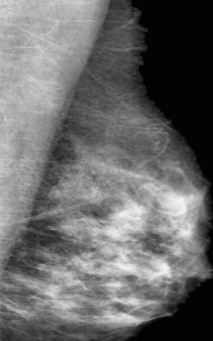

In [6]:
import cv2
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

def crop_resize(path, out):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None:
        return False
    blur = cv2.GaussianBlur(im, (5, 5), 0)
    _, th = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        x, y, w, h = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        im = im[y:y + h, x:x + w]
    im = cv2.resize(im, (IMG_W, IMG_H), interpolation=cv2.INTER_AREA)
    cv2.imwrite(out, im)
    return True

print("original size of first image:", cv2.imread(sub.img_path.iloc[0], cv2.IMREAD_GRAYSCALE).shape)

os.makedirs(PROC, exist_ok=True)
sub["proc_path"] = PROC + "/" + sub.name
with ThreadPoolExecutor(8) as ex:
    ok = list(tqdm(ex.map(lambda r: crop_resize(r.img_path, r.proc_path), sub.itertuples()), total=len(sub)))
sub = sub[np.array(ok)].reset_index(drop=True)
print(len(sub), "images processed")

sub.drop(columns="tags").to_csv(f"{WORK}/manifest.csv", index=False)

from PIL import Image
Image.open(sub.proc_path.iloc[0]).resize((IMG_W // 3, IMG_H // 3))   # eyeball the crop

In [8]:
!pip -q install efficientnet_pytorch

import torch, torch.nn as nn
from huggingface_hub import hf_hub_download
from efficientnet_pytorch import EfficientNet

CKPT_FILE = "Pre-trained-checkpoints/b5-model-best-epoch-7.tar"
ckpt_path = hf_hub_download("shawn24/Mammo-CLIP", CKPT_FILE, local_dir=f"{WORK}/ckpt")
ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
sd = ck["model"]
enc_sd = {k.split("image_encoder.", 1)[1].removeprefix("model."): v
          for k, v in sd.items() if "image_encoder" in k}
print(len(enc_sd), "image-encoder tensors; sample:", list(enc_sd)[:3])

class Enc(nn.Module):
    """Wraps the encoder so it returns pooled features; property names match what the training code uses."""
    def __init__(self, m):
        super().__init__()
        self.m = m
        self.num_features = m._conv_head.out_channels
    def forward(self, x):
        return self.m._avg_pooling(self.m.extract_features(x)).flatten(1)
    @property
    def blocks(self): return self.m._blocks
    @property
    def conv_head(self): return self.m._conv_head
    @property
    def bn2(self): return self.m._bn1


852 image-encoder tensors; sample: ['_conv_stem.weight', '_bn0.weight', '_bn0.bias']


In [9]:
m = EfficientNet.from_name("efficientnet-b5")
miss, unexp = m.load_state_dict(enc_sd, strict=False)
print("missing:", len(miss), miss[:8])
print("unexpected:", len(unexp), unexp[:8])

def _ok(k): return "num_batches_tracked" not in k and not k.startswith("_fc")

def load_backbone(init):
    if init == "mammoclip":
        m = EfficientNet.from_name("efficientnet-b5")
        miss, unexp = m.load_state_dict(enc_sd, strict=False)
        miss = [k for k in miss if _ok(k)]
        print("missing (excluding _fc):", len(miss), miss[:4])
        assert not miss, "Weights did not load; paste the printed lines."
    elif init == "imagenet":
        m = EfficientNet.from_pretrained("efficientnet-b5")
    else:
        m = EfficientNet.from_name("efficientnet-b5")
    return Enc(m)

_ = load_backbone("mammoclip")

missing: 2 ['_fc.weight', '_fc.bias']
unexpected: 0 []
missing (excluding _fc): 0 []


In [11]:
from pyexpat import model

import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score
import torchvision.transforms.functional as TF
from torchvision.transforms import v2 as T

LABELS = ["malignant", "mass", "calc"]
dev = "cuda"
# normalization constants from Mammo-CLIP 
MEAN, STD = 0.3089279, 0.25053555408335154

class DS(torch.utils.data.Dataset):
    def __init__(self, df, train):
        self.df, self.train = df.reset_index(drop=True), train
        self.aug = T.Compose([T.RandomHorizontalFlip(),
                              T.RandomAffine(degrees=7, translate=(0.03, 0.03), scale=(0.95, 1.05)),
                              T.ColorJitter(brightness=0.15, contrast=0.15)])
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        im = Image.open(r.proc_path).convert("L")
        if self.train: im = self.aug(im)
        x = (TF.to_tensor(im) - MEAN) / STD
        y = torch.tensor([r.malignant, r.mass, r.calc], dtype=torch.float32)
        return x.repeat(3, 1, 1), y

class Net(nn.Module):
    def __init__(self, bb, n_out=len(LABELS)):
        super().__init__()
        self.bb, self.head, self.frozen = bb, nn.Linear(bb.num_features, n_out), True
    def forward(self, x):
        if self.frozen:
            with torch.no_grad(): f = self.bb(x)
        else:
            f = self.bb(x)
        return self.head(f)

def set_bn_eval(m):
    for mod in m.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm): mod.eval()

def predict(model, df, bs=4):
    model.eval()
    ps, ys = [], []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for x, y in DataLoader(DS(df, False), batch_size=bs, num_workers=2):
            ps.append(torch.sigmoid(model(x.to(dev)).float()).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

def aucs(y, p):
    return {n: (roc_auc_score(y[:, i], p[:, i]) if len(np.unique(y[:, i])) > 1 else float("nan"))
            for i, n in enumerate(LABELS)}

def train(model, tr, va, epochs, lr_head, lr_bb, bs, accum, tag, unfreeze=False):
    model.to(dev)
    for p in model.bb.parameters(): p.requires_grad = False
    model.frozen = not unfreeze
    groups = [{"params": model.head.parameters(), "lr": lr_head}]
    if unfreeze:   # last two blocks + head conv; BN statistics stay frozen (tiny batches)
        ps = [p for m in (model.bb.blocks[-2:], model.bb.conv_head, model.bb.bn2) for p in m.parameters()]
        for p in ps: p.requires_grad = True
        groups.append({"params": ps, "lr": lr_bb})
    opt = torch.optim.AdamW(groups, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    freq = tr[LABELS].values.mean(0)
    pw = torch.tensor((1 - freq) / np.clip(freq, 1e-3, None), dtype=torch.float32, device=dev).clamp(max=10)
    crit = nn.BCEWithLogitsLoss(pos_weight=pw)
    scaler = torch.amp.GradScaler("cuda")
    dl = DataLoader(DS(tr, True), batch_size=bs, shuffle=True, num_workers=2, drop_last=True)
    best = -1
    for ep in range(epochs):
        model.train()
        if model.frozen:
            model.bb.eval()          # fully frozen encoder: no random dropping
        else:
            set_bn_eval(model.bb)
            
        t0, tot = time.time(), 0.0
        opt.zero_grad()
        for i, (x, y) in enumerate(dl):
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = crit(model(x).float(), y) / accum
            scaler.scale(loss).backward(); tot += loss.item() * accum
            if (i + 1) % accum == 0:
                scaler.step(opt); scaler.update(); opt.zero_grad()
        sched.step()
        yv, pv = predict(model, va); a = aucs(yv, pv); score = np.nanmean(list(a.values()))
        print(f"[{tag}] ep {ep+1}/{epochs} loss {tot/len(dl):.3f} val AUC " +
              " ".join(f"{k}={v:.3f}" for k, v in a.items()) + f" | {time.time()-t0:.0f}s")
        if score > best:
            best = score; torch.save(model.state_dict(), f"{WORK}/{tag}_best.pt")
    model.load_state_dict(torch.load(f"{WORK}/{tag}_best.pt"))
    return model

def boot_auc(y, p, groups, n=1000):
    rng = np.random.default_rng(0)
    ug = np.unique(groups); idx = {g: np.where(groups == g)[0] for g in ug}; out = []
    for _ in range(n):   # resample participants, not images
        ii = np.concatenate([idx[g] for g in rng.choice(ug, len(ug))])
        if len(np.unique(y[ii])) > 1: out.append(roc_auc_score(y[ii], p[ii]))
    return np.percentile(out, [2.5, 97.5])

def report(model, df, name):
    y, p = predict(model, df); a = aucs(y, p)
    for i, n in enumerate(LABELS):
        if np.isnan(a[n]): print(f"{name:14s} {n:10s} n/a (single class in this split)"); continue
        lo, hi = boot_auc(y[:, i], p[:, i], df.participant.values)
        print(f"{name:14s} {n:10s} AUC {a[n]:.3f} [{lo:.3f}, {hi:.3f}]  positives={int(y[:, i].sum())}/{len(y)}")

tr, va, te = [sub[sub.split == s] for s in ("train", "val", "test")]

In [12]:
lp = train(Net(load_backbone("mammoclip")), tr, va, epochs=15, lr_head=1e-3, lr_bb=0, bs=4, accum=2, tag="lp_mammoclip")

missing (excluding _fc): 0 []
[lp_mammoclip] ep 1/15 loss 0.721 val AUC malignant=0.555 mass=0.553 calc=0.566 | 39s
[lp_mammoclip] ep 2/15 loss 0.704 val AUC malignant=0.570 mass=0.546 calc=0.553 | 33s
[lp_mammoclip] ep 3/15 loss 0.685 val AUC malignant=0.577 mass=0.556 calc=0.563 | 34s
[lp_mammoclip] ep 4/15 loss 0.683 val AUC malignant=0.590 mass=0.542 calc=0.546 | 34s
[lp_mammoclip] ep 5/15 loss 0.668 val AUC malignant=0.590 mass=0.549 calc=0.554 | 34s
[lp_mammoclip] ep 6/15 loss 0.663 val AUC malignant=0.605 mass=0.555 calc=0.562 | 34s
[lp_mammoclip] ep 7/15 loss 0.661 val AUC malignant=0.605 mass=0.550 calc=0.555 | 35s
[lp_mammoclip] ep 8/15 loss 0.656 val AUC malignant=0.609 mass=0.558 calc=0.562 | 35s
[lp_mammoclip] ep 9/15 loss 0.655 val AUC malignant=0.612 mass=0.557 calc=0.562 | 35s
[lp_mammoclip] ep 10/15 loss 0.649 val AUC malignant=0.615 mass=0.551 calc=0.560 | 35s
[lp_mammoclip] ep 11/15 loss 0.646 val AUC malignant=0.615 mass=0.556 calc=0.561 | 35s
[lp_mammoclip] ep 12/1

In [13]:
del lp; torch.cuda.empty_cache()
ft = Net(load_backbone("mammoclip"))
ft.load_state_dict(torch.load(f"{WORK}/lp_mammoclip_best.pt"))
ft = train(ft, tr, va, epochs=10, lr_head=1e-4, lr_bb=1e-5, bs=2, accum=4, tag="ft_mammoclip", unfreeze=True)

missing (excluding _fc): 0 []
[ft_mammoclip] ep 1/10 loss 0.656 val AUC malignant=0.616 mass=0.562 calc=0.567 | 39s
[ft_mammoclip] ep 2/10 loss 0.650 val AUC malignant=0.619 mass=0.560 calc=0.565 | 38s
[ft_mammoclip] ep 3/10 loss 0.649 val AUC malignant=0.624 mass=0.562 calc=0.568 | 38s
[ft_mammoclip] ep 4/10 loss 0.637 val AUC malignant=0.624 mass=0.572 calc=0.572 | 39s
[ft_mammoclip] ep 5/10 loss 0.641 val AUC malignant=0.628 mass=0.573 calc=0.575 | 39s
[ft_mammoclip] ep 6/10 loss 0.628 val AUC malignant=0.630 mass=0.570 calc=0.572 | 39s
[ft_mammoclip] ep 7/10 loss 0.644 val AUC malignant=0.631 mass=0.568 calc=0.570 | 39s
[ft_mammoclip] ep 8/10 loss 0.623 val AUC malignant=0.632 mass=0.569 calc=0.571 | 39s
[ft_mammoclip] ep 9/10 loss 0.629 val AUC malignant=0.633 mass=0.570 calc=0.570 | 39s
[ft_mammoclip] ep 10/10 loss 0.622 val AUC malignant=0.633 mass=0.570 calc=0.571 | 39s


In [14]:
del ft; torch.cuda.empty_cache()
base = train(Net(load_backbone("imagenet")), tr, va, epochs=15, lr_head=1e-3, lr_bb=0, bs=4, accum=2, tag="lp_imagenet")

Downloading: "https://github.com/lukemelas/EfficientNet-PyTorch/releases/download/1.0/efficientnet-b5-b6417697.pth" to /root/.cache/torch/hub/checkpoints/efficientnet-b5-b6417697.pth


100%|██████████| 117M/117M [00:01<00:00, 68.0MB/s] 


Loaded pretrained weights for efficientnet-b5
[lp_imagenet] ep 1/15 loss 0.741 val AUC malignant=0.541 mass=0.613 calc=0.603 | 34s
[lp_imagenet] ep 2/15 loss 0.723 val AUC malignant=0.596 mass=0.629 calc=0.618 | 34s
[lp_imagenet] ep 3/15 loss 0.714 val AUC malignant=0.602 mass=0.619 calc=0.616 | 35s
[lp_imagenet] ep 4/15 loss 0.706 val AUC malignant=0.600 mass=0.623 calc=0.627 | 35s
[lp_imagenet] ep 5/15 loss 0.698 val AUC malignant=0.577 mass=0.631 calc=0.629 | 35s
[lp_imagenet] ep 6/15 loss 0.696 val AUC malignant=0.594 mass=0.622 calc=0.625 | 35s
[lp_imagenet] ep 7/15 loss 0.696 val AUC malignant=0.612 mass=0.610 calc=0.610 | 35s
[lp_imagenet] ep 8/15 loss 0.685 val AUC malignant=0.619 mass=0.625 calc=0.626 | 35s
[lp_imagenet] ep 9/15 loss 0.683 val AUC malignant=0.618 mass=0.618 calc=0.620 | 35s
[lp_imagenet] ep 10/15 loss 0.678 val AUC malignant=0.612 mass=0.615 calc=0.618 | 35s
[lp_imagenet] ep 11/15 loss 0.675 val AUC malignant=0.621 mass=0.610 calc=0.611 | 35s
[lp_imagenet] ep 

In [15]:
for tag, init, name in [("lp_mammoclip", "mammoclip", "LP Mammo-CLIP"),
                        ("ft_mammoclip", "mammoclip", "FT Mammo-CLIP"),
                        ("lp_imagenet",  "imagenet",  "LP ImageNet")]:
    m = Net(load_backbone(init))
    m.load_state_dict(torch.load(f"{WORK}/{tag}_best.pt"))
    m.to(dev)
    report(m, te, name)
    del m; torch.cuda.empty_cache()

missing (excluding _fc): 0 []
LP Mammo-CLIP  malignant  AUC 0.676 [0.564, 0.782]  positives=51/128
LP Mammo-CLIP  mass       AUC 0.678 [0.571, 0.778]  positives=68/128
LP Mammo-CLIP  calc       AUC 0.680 [0.573, 0.780]  positives=60/128
missing (excluding _fc): 0 []
FT Mammo-CLIP  malignant  AUC 0.673 [0.558, 0.777]  positives=51/128
FT Mammo-CLIP  mass       AUC 0.688 [0.581, 0.786]  positives=68/128
FT Mammo-CLIP  calc       AUC 0.686 [0.579, 0.786]  positives=60/128
Loaded pretrained weights for efficientnet-b5
LP ImageNet    malignant  AUC 0.653 [0.541, 0.761]  positives=51/128
LP ImageNet    mass       AUC 0.626 [0.512, 0.746]  positives=68/128
LP ImageNet    calc       AUC 0.631 [0.512, 0.752]  positives=60/128
